# 01 · Comprendre la fitness

La **fitness** est le nombre renvoyé par `fitness_inner(mapping, circuit, backend)` dans `source.py`. C'est ce qu'il faut **minimiser**.

Pour un placement donné (`mapping[i]` = qubit physique du qubit logique `i`), Qiskit :

1. **traduit** les portes du circuit en portes que la puce sait exécuter (`h` → `rz`, `sx`, `rz` ; `cp`, `swap`… → `cx` + rotations) ;
2. **route** le circuit : chaque fois qu'une porte à 2 qubits porte sur deux qubits **non voisins** sur la puce, il insère des `SWAP` (3 `cx` chacun) pour les rapprocher ;
3. **optimise** le résultat ;
4. renvoie la **profondeur** du circuit obtenu : le nombre de couches de portes exécutées en parallèle, c'est-à-dire sa durée.

Un bon placement met côte à côte les qubits qui interagissent souvent → moins de `SWAP` → circuit moins profond.

In [1]:
import numpy as np
import pandas as pd

# Pont vers source.py et extraction de statistiques de circuit.
from goc import circuit_data, source_bridge
# Chargement des instances, vraie fitness, coût de distance.
from optimizer import Problem, available_instances, distance_cost, load_instance
# Outils de représentation : permutations aléatoires, échanges, conversion en placement.
from optimizer.representation import random_permutation, random_swap_indices, swap, to_mapping

# Générateur aléatoire avec graine fixe : les placements tirés sont les mêmes à chaque exécution.
rng = np.random.default_rng(0)

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## 1. Ce que fait `fitness_inner`, sur l'instance 1

Le circuit d'origine (Deutsch-Jozsa, 12 qubits) : les qubits `q0` à `q10` interagissent tous avec `q11`.

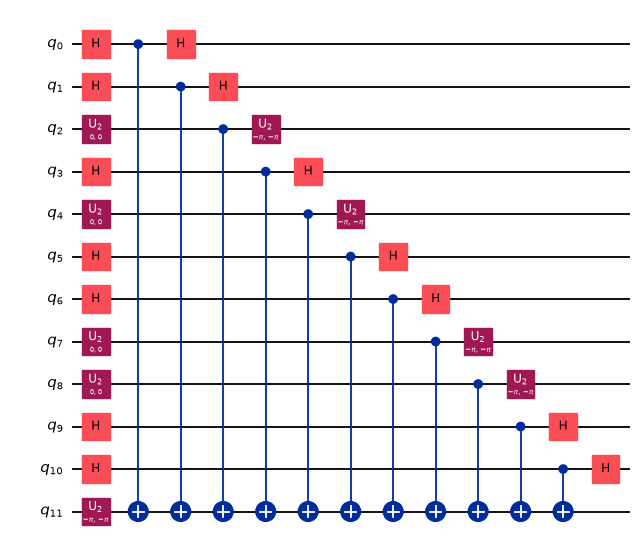

In [3]:
instance = load_instance(1)
# Dessin du circuit avec Qiskit (fold=-1 : sur une seule ligne).
drawing = instance.circuit.draw("mpl", fold=-1, scale=0.6)
plt.close(drawing)
drawing

On applique la même chaîne que `fitness_inner` avec le placement identité `[0, 1, …, 11]`, mais on récupère le circuit transformé au lieu de sa seule profondeur.

In [4]:
def describe(circuit):
    """Résumé lisible d'un circuit : qubits, profondeur, portes, portes à 2 qubits, types de portes."""
    summary = circuit_data.summary(circuit)
    counts = sorted(summary["gateCounts"].items(), key=lambda kv: -kv[1])
    return {
        "qubits": summary["numQubits"],
        "depth": summary["depth"],
        "gates": summary["size"],
        "2-qubit gates": summary["twoQubitGates"],
        "gate types": ", ".join(f"{name} {count}" for name, count in counts),
    }


# Placement identité : qubit logique i sur qubit physique i.
identity = list(range(instance.n))
# Circuit routé par la même chaîne que fitness_inner.
routed = source_bridge.routed_circuit(identity, instance.circuit, instance.backend)
# Comparaison avant / après, en texte pour un affichage homogène.
circuit_comparison = pd.DataFrame({"original circuit": describe(instance.circuit), "after fitness_inner (identity)": describe(routed)}).astype(str)
circuit_comparison

,original circuit,after fitness_inner (identity)
qubits,12,16
depth,13,57
gates,34,129
2-qubit gates,11,51
gate types,"h 14, cx 11, u2 9","cx 51, rz 49, sx 27, x 2"


**Lecture :**
- le circuit routé vit sur les 16 qubits de la puce, plus sur 12 qubits logiques ;
- les portes ont été traduites (`h`, `u2` → `rz`, `sx`, `x`) ;
- il y a beaucoup plus de `cx` qu'au départ : ce sont les `SWAP` ajoutés par le routage ;
- la **profondeur** du circuit routé est la fitness.

Même avec un placement parfait, la fitness reste plus grande que la profondeur logique, à cause de la traduction des portes. Ce qu'on peut réduire, c'est la partie due aux `SWAP`.

## 2. Toutes les instances : profondeur avant et après routage

Pour chaque instance : la profondeur logique, puis la fitness (une seule évaluation) du placement identité et d'un placement aléatoire. Le **coût de distance** est l'indicateur instantané Σ portes × (distance sur la puce − 1).

In [5]:
rows = []
for instance_id in available_instances():
    inst = load_instance(instance_id)
    problem = Problem(inst)
    identity = list(range(inst.n))
    # Placement aléatoire : les n premiers éléments d'une permutation aléatoire de range(m).
    random_mapping = to_mapping(random_permutation(inst.m, rng), inst.n)
    rows.append({
        "instance": instance_id,
        "n": inst.n,
        "m": inst.m,
        "hardware": inst.hardware_name,
        "2q gates": inst.two_qubit_gates,
        "logical_depth": inst.logical_depth,
        # Une seule vraie évaluation de chaque placement.
        "identity_fitness": problem.fitness(identity),
        "random_fitness": problem.fitness(random_mapping),
        # Coût de distance (gratuit) des mêmes placements.
        "identity_distance_cost": distance_cost(inst, identity),
        "random_distance_cost": distance_cost(inst, random_mapping),
    })
# Tableau : une ligne par instance.
overview = pd.DataFrame(rows).set_index("instance")
overview

,n,m,hardware,2q gates,logical_depth,identity_fitness,random_fitness,identity_distance_cost,random_distance_cost
instance,,,,,,,,,
1,12,16,custom_basis_backend,11,13,57,67,19,24
2,16,16,custom_basis_backend,150,71,59,209,0,340
3,10,16,custom_basis_backend,50,20,149,212,124,128
4,19,20,fake_20q_v1,18,19,63,53,59,26
5,12,20,fake_20q_v1,148,127,386,393,274,282
6,14,20,fake_20q_v1,28,9,98,81,56,80
7,20,27,fake_27q_pulse_v1,19,20,107,156,40,60
8,20,27,fake_27q_pulse_v1,20,5,74,59,56,88
9,25,27,fake_27q_pulse_v1,24,25,137,198,50,88


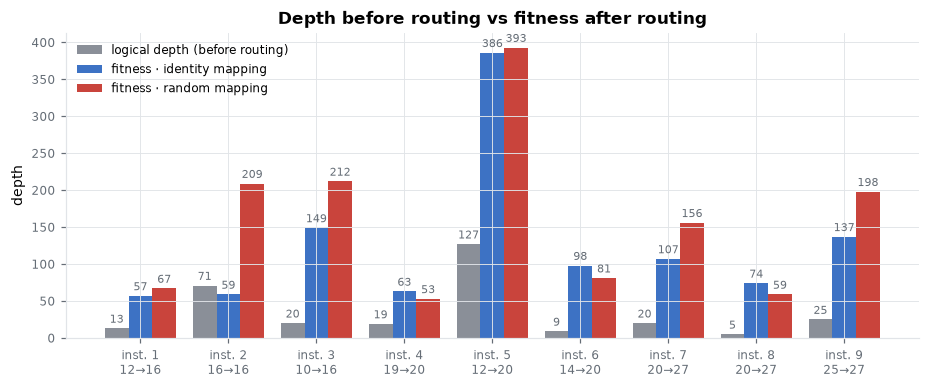

In [6]:
def plot_depth_overview(frame):
    """Diagramme en barres : profondeur logique, fitness de l'identité et d'un placement aléatoire, par instance."""
    fig, ax = plt.subplots(figsize=(10, 3.6))
    x = np.arange(len(frame))
    series = [
        ("logical_depth", "logical depth (before routing)", PALETTE[5]),
        ("identity_fitness", "fitness · identity mapping", PALETTE[0]),
        ("random_fitness", "fitness · random mapping", PALETTE[3]),
    ]
    width = 0.27
    # Trois barres par instance, décalées horizontalement.
    for offset, (column, label, color) in zip((-width, 0, width), series):
        bars = ax.bar(x + offset, frame[column], width, label=label, color=color)
        # Valeur écrite au-dessus de chaque barre.
        ax.bar_label(bars, fontsize=7, color=MUTED, padding=2)
    ax.set_xticks(x, [f"inst. {i}\n{n}→{m}" for i, n, m in zip(frame.index, frame["n"], frame["m"])])
    ax.set_ylabel("depth")
    ax.set_title("Depth before routing vs fitness after routing")
    ax.legend(loc="upper left")
    return fig


plot_depth_overview(overview);

Le placement a un effet énorme sur certaines instances (aléatoire bien pire que l'identité), et presque aucun sur d'autres. L'écart entre profondeur logique et fitness donne une idée de la marge à gagner.

## 3. Le placement change la fitness… et la même évaluation varie

Sur l'instance 5, trois placements sont évalués **30 fois chacun** :
- un placement **aléatoire** ;
- le placement **identité** ;
- un placement **optimisé pour le coût de distance** : une descente de 3000 échanges qui ne garde un échange que s'il ne dégrade pas le coût de distance. Aucune vraie évaluation n'est utilisée.

In [7]:
def surrogate_descent(instance, permutation, steps, rng):
    """Améliore une permutation par `steps` échanges aléatoires gardés s'ils ne dégradent pas le coût de distance."""
    current = permutation.copy()
    current_cost = distance_cost(instance, current[: instance.n])
    for _ in range(steps):
        candidate = swap(current, *random_swap_indices(instance.n, instance.m, rng))
        cost = distance_cost(instance, candidate[: instance.n])
        if cost <= current_cost:
            current, current_cost = candidate, cost
    return current


instance = load_instance(5)
problem = Problem(instance)
# Les trois placements comparés.
candidates = {
    "random": to_mapping(random_permutation(instance.m, rng), instance.n),
    "identity": list(range(instance.n)),
    "distance-optimised": to_mapping(surrogate_descent(instance, random_permutation(instance.m, rng), 3000, rng), instance.n),
}
RUNS = 30
# Une ligne par évaluation : placement, son coût de distance, numéro de l'essai, fitness obtenue.
samples = pd.DataFrame([
    {"label": label, "distance_cost": distance_cost(instance, mapping), "run": run, "cost": problem.fitness(mapping)}
    for label, mapping in candidates.items()
    for run in range(RUNS)
])
# Statistiques par placement (sort=False garde l'ordre random, identity, distance-optimised).
distribution_summary = samples.groupby("label", sort=False).agg(
    distance_cost=("distance_cost", "first"),
    mean=("cost", "mean"),
    std=("cost", "std"),
    min=("cost", "min"),
    max=("cost", "max"),
).round(1)
distribution_summary

,distance_cost,mean,std,min,max
label,,,,,
random,412,389.7,16.8,357,403
identity,274,372.2,20.5,338,390
distance-optimised,107,381.7,5.1,372,387


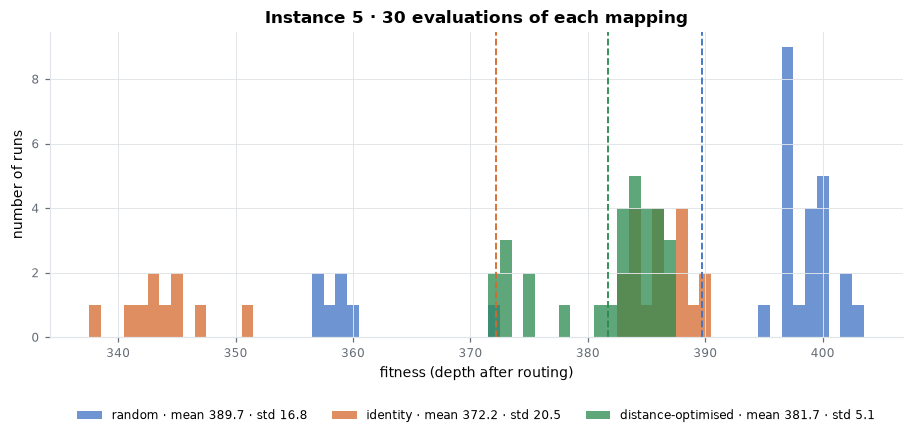

In [8]:
def plot_mapping_distributions(samples, title):
    """Histogramme des fitness obtenues pour chaque placement (une couleur par placement, moyenne en pointillés)."""
    fig, ax = plt.subplots(figsize=(10, 3.6))
    labels = list(dict.fromkeys(samples["label"]))
    # Une classe d'histogramme par valeur entière de fitness.
    bins = np.arange(samples["cost"].min() - 0.5, samples["cost"].max() + 1.5, 1)
    for color, label in zip(PALETTE, labels):
        costs = samples.loc[samples["label"] == label, "cost"]
        ax.hist(costs, bins=bins, alpha=0.75, color=color, label=f"{label} · mean {costs.mean():.1f} · std {costs.std():.1f}")
        ax.axvline(costs.mean(), color=color, linewidth=1.2, linestyle="--")
    ax.set_xlabel("fitness (depth after routing)")
    ax.set_ylabel("number of runs")
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=len(labels))
    return fig


plot_mapping_distributions(samples, "Instance 5 · 30 evaluations of each mapping");

**Deux constats :**

1. **Le bruit.** Un même placement ne donne pas toujours la même fitness. L'étape de routage de Qiskit (Sabre) fait des choix aléatoires, et `source.py` ne fixe pas la graine. Une seule évaluation est donc un tirage au sort autour d'une valeur moyenne, avec parfois plusieurs « modes » nettement séparés.
2. **Le placement compte**, mais les distributions peuvent se chevaucher. Avec une seule évaluation par placement, on peut conclure à tort qu'un placement est meilleur qu'un autre. Et un bon coût de distance ne garantit pas une bonne fitness : sur l'instance 5, le placement optimisé pour la distance n'est en général pas meilleur que les autres.

Le notebook `02_noise_and_surrogate` mesure ces deux effets sur toutes les instances.